In this assignment, i will be using the Telco Customer Churn Dataset.
The Telco Customer Churn Dataset is an IBM dataset describing customers of a fictional telecommunications company and whether they stopped using its services.

The dataset contains 7,043 customer records and 21 columns, with Churn as the target indicating whether a customer left within the previous month. There are Non-churned customers of 5,174 (73.5%) and Churned customers of	1,869 (26.5%) making the dataset highly imbalanced.

The goal of this assignment is to apply techniques to balance the dataset.

In [1]:
#Improt the necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve
)

from imblearn.over_sampling import SMOTE

In [2]:
#Load the dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**Split the dataset into features and target**

In [4]:
# Convert target variable into binary values
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# Separate features and target
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

# Split dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (5634, 19)
Testing Features: (1409, 19)
Training Target: (5634,)
Testing Target: (1409,)


**Explore Dataset**

In [5]:
# First five rows of training data
display(X_train.head())

# Dataset information
X_train.info()

# Summary statistics
display(X_train.describe(include="all"))

# Check missing values
print("Missing Values:")
print(X_train.isnull().sum())

# Check class distribution
print("Class Distribution:")
print(y_train.value_counts())

# Class percentages
print("Class Percentages:")
print(y_train.value_counts(normalize=True) * 100)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
3738,Male,0,No,No,35,No,No phone service,DSL,No,No,Yes,No,Yes,Yes,Month-to-month,No,Electronic check,49.20,1701.65
3151,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,75.10,1151.55
4860,Male,0,Yes,Yes,13,No,No phone service,DSL,Yes,Yes,No,Yes,No,No,Two year,No,Mailed check,40.55,590.35
3867,Female,0,Yes,No,26,Yes,No,DSL,No,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),73.50,1905.70
3810,Male,0,Yes,Yes,1,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Electronic check,44.55,44.55


<class 'pandas.DataFrame'>
Index: 5634 entries, 3738 to 5639
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            5634 non-null   str    
 1   SeniorCitizen     5634 non-null   int64  
 2   Partner           5634 non-null   str    
 3   Dependents        5634 non-null   str    
 4   tenure            5634 non-null   int64  
 5   PhoneService      5634 non-null   str    
 6   MultipleLines     5634 non-null   str    
 7   InternetService   5634 non-null   str    
 8   OnlineSecurity    5634 non-null   str    
 9   OnlineBackup      5634 non-null   str    
 10  DeviceProtection  5634 non-null   str    
 11  TechSupport       5634 non-null   str    
 12  StreamingTV       5634 non-null   str    
 13  StreamingMovies   5634 non-null   str    
 14  Contract          5634 non-null   str    
 15  PaperlessBilling  5634 non-null   str    
 16  PaymentMethod     5634 non-null   str    
 17  MonthlyC

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
count,5634,5634.000000,5634,5634,5634.000000,5634,5634,5634,5634,5634,5634,5634,5634,5634,5634,5634,5634,5634.000000,5626.000000
unique,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,NaN
top,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,NaN
freq,2833,NaN,2905,3955,NaN,5075,2685,2483,2797,2442,2472,2771,2226,2217,3102,3331,1891,NaN,NaN
mean,NaN,0.163294,NaN,NaN,32.485091,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.929961,2302.604266
std,NaN,0.369667,NaN,NaN,24.568744,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.138105,2279.173176
min,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.400000,18.850000
25%,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.662500,407.275000
50%,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.500000,1398.125000
75%,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,90.000000,3838.612500


Missing Values:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        8
dtype: int64
Class Distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64
Class Percentages:
Churn
0    73.464679
1    26.535321
Name: proportion, dtype: float64


Missing values exist in the Total charges column. non-churned customers are more than Churn customers. This means the dataset is imbalanced and therefore, the model could achived a high accuracy predicting correctly the majority class (no churn)

**Visualize class distribution**

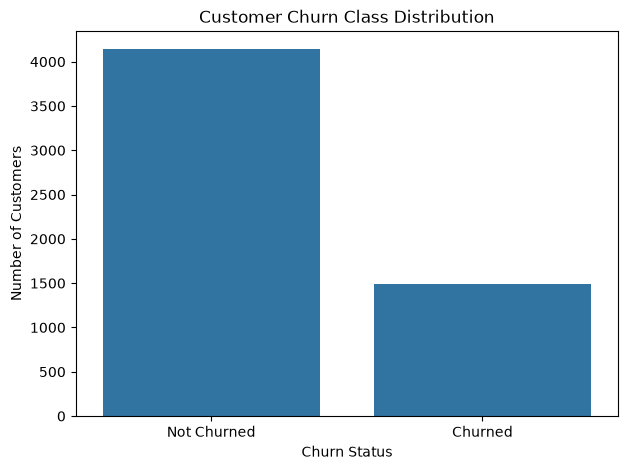

In [6]:
plt.figure(figsize=(7, 5))

sns.countplot(x=y_train, order=[0, 1])

plt.title("Customer Churn Class Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.xticks([0, 1], ["Not Churned", "Churned"])

plt.show()

The bar chart illustrates the imbalance between customers who churned and those who remained. The non-churned class is significantly larger than the churned class

**Preprocess the training and testing data**

In [7]:
# Convert TotalCharges to numeric
X_train = X_train.copy()
X_test = X_test.copy()

X_train["TotalCharges"] = pd.to_numeric(
    X_train["TotalCharges"], errors="coerce"
)

X_test["TotalCharges"] = pd.to_numeric(
    X_test["TotalCharges"], errors="coerce"
)

In [8]:
#handle missing values and encode categorical variables
# Identify numerical and categorical features
num_cols = X_train.select_dtypes(
    include=np.number
).columns

cat_cols = X_train.select_dtypes(
    exclude=np.number
).columns

# Numerical preprocessing
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

# Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data
X_test_processed = preprocessor.transform(X_test)

print("Training Shape:", X_train_processed.shape)
print("Testing Shape:", X_test_processed.shape)

Training Shape: (5634, 45)
Testing Shape: (1409, 45)


**Train a baseline Random Forest model**
The baseline model is trained without handling the data imbalnace.

In [9]:
# Initialize baseline Random Forest
rf_baseline = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train model
rf_baseline.fit(X_train_processed, y_train)

# Predict test data
y_pred_baseline = rf_baseline.predict(X_test_processed)

# Predict probabilities
y_prob_baseline = rf_baseline.predict_proba(
    X_test_processed
)[:, 1]

# Evaluate
print("Baseline Random Forest Results")
print(classification_report(
    y_test,
    y_pred_baseline,
    target_names=["Not Churned", "Churned"]
))

print("ROC-AUC:", roc_auc_score(y_test, y_prob_baseline))

Baseline Random Forest Results
              precision    recall  f1-score   support

 Not Churned       0.82      0.89      0.85      1035
     Churned       0.60      0.48      0.53       374

    accuracy                           0.78      1409
   macro avg       0.71      0.68      0.69      1409
weighted avg       0.77      0.78      0.77      1409

ROC-AUC: 0.8169831305381177


Accuracy: The model correctly classified 78% of customers.
Precision: About 60% of customers predicted to churn actually churned. and 82% were correctly predicted as not churned
Recall: The model identified only 48% of customers who actually churned, meaning it missed more than half. but the model identified 89% of customers who were not churned.  meaning it missed about 11%.
F1-score of 53% for churned indicates a weak balance between precision and recall. while for not churned it achieved 85%.
ROC-AUC (81.70%): Shows reasonably good ability to distinguish churned from non-churned customers.

**Apply SMOTE**

In [10]:
# Apply SMOTE to training data only
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_processed,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(pd.Series(y_train_smote).value_counts())

Before SMOTE:
Churn
0    4139
1    1495
Name: count, dtype: int64

After SMOTE:
Churn
0    4139
1    4139
Name: count, dtype: int64


**Train Random Forest on SMOTE-resampled data**

In [11]:
rf_smote = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train on balanced data
rf_smote.fit(X_train_smote, y_train_smote)

# Predict on original test data
y_pred_smote = rf_smote.predict(X_test_processed)

y_prob_smote = rf_smote.predict_proba(
    X_test_processed
)[:, 1]

# Evaluate
print("Random Forest with SMOTE Results")
print(classification_report(
    y_test,
    y_pred_smote,
    target_names=["Not Churned", "Churned"]
))

print("ROC-AUC:", roc_auc_score(y_test, y_prob_smote))

Random Forest with SMOTE Results
              precision    recall  f1-score   support

 Not Churned       0.83      0.88      0.85      1035
     Churned       0.60      0.50      0.54       374

    accuracy                           0.78      1409
   macro avg       0.71      0.69      0.70      1409
weighted avg       0.77      0.78      0.77      1409

ROC-AUC: 0.8174739724611846


In [ ]:
Accuracy of 78%: is identical to the baseline model.
Precision of 60%: Also identical to the baseline.
Recall of 50%: Improved from 48%, indicating that SMOTE helped identify more churned customers.
F1-score of 54%: Slight improvement over the baseline.
ROC-AUC of 81.75%: A slight improvement in class discrimination.

**Implement Class Weights**
Note that class weights address imbalance by assigning greater importance to the minority class during training

In [12]:
rf_weighted = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)

# Train model
rf_weighted.fit(X_train_processed, y_train)

# Predictions
y_pred_weighted = rf_weighted.predict(X_test_processed)

y_prob_weighted = rf_weighted.predict_proba(
    X_test_processed
)[:, 1]

# Evaluate
print("Random Forest with Class Weights Results")
print(classification_report(
    y_test,
    y_pred_weighted,
    target_names=["Not Churned", "Churned"]
))

print("ROC-AUC:", roc_auc_score(y_test, y_prob_weighted))

Random Forest with Class Weights Results
              precision    recall  f1-score   support

 Not Churned       0.86      0.82      0.84      1035
     Churned       0.56      0.62      0.59       374

    accuracy                           0.77      1409
   macro avg       0.71      0.72      0.71      1409
weighted avg       0.78      0.77      0.77      1409

ROC-AUC: 0.8210558268103025


Accuracy of 77%: Same as the other models.
Precision of 56%: Lowest among the three models, indicating more false-positive churn predictions.
Recall of 62%: Highest recall, meaning the model identified approximately 62 out of every 100 customers who actually churned.
F1-score of 59%: Highest F1-score, showing the best balance between precision and recall.
ROC-AUC of 82.11%: Highest ROC-AUC, although the difference is small.

**Compare the three methods**

In [13]:
results = []

models = {
    "Baseline Random Forest": (
        y_pred_baseline, y_prob_baseline
    ),
    "Random Forest + SMOTE": (
        y_pred_smote, y_prob_smote
    ),
    "Random Forest + Class Weights": (
        y_pred_weighted, y_prob_weighted
    )
}

for name, (pred, prob) in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Baseline Random Forest,0.7779,0.6034,0.4759,0.5321,0.8170
1,Random Forest + SMOTE,0.7771,0.5955,0.5000,0.5436,0.8175
2,Random Forest + Class Weights,0.7693,0.5588,0.6230,0.5891,0.8211


Class weighting substantially improved the identification of churned customers while slightly reducing accuracy and precision.

**Visualize Performance**

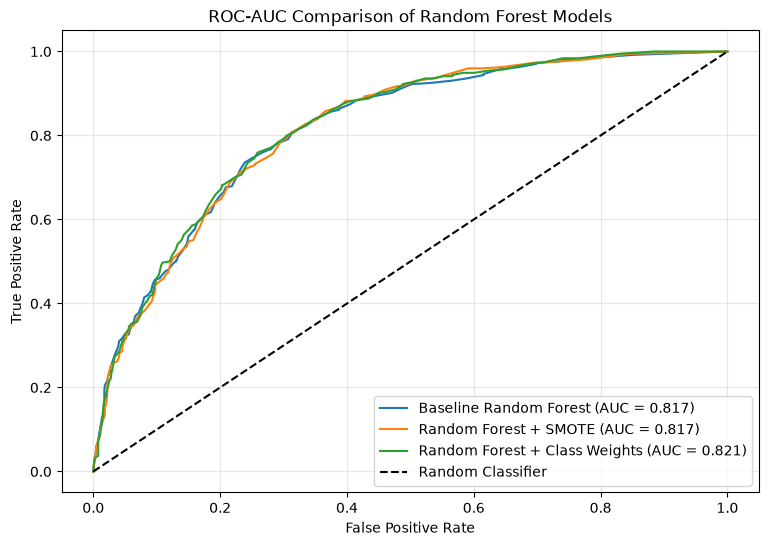

In [14]:
plt.figure(figsize=(9, 6))

for name, (pred, prob) in models.items():

    fpr, tpr, _ = roc_curve(y_test, prob)

    auc = roc_auc_score(y_test, prob)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.title("ROC-AUC Comparison of Random Forest Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

The 3 curves overlap considerably, indicating that the balancing techniques produced only minor improvements in overall discrimination. However, the Class-Weighted Random Forest achieved the highest ROC-AUC of 0.821.